## 1. Imports, configuration, seed, and reproducibility


In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys
from pathlib import Path

requirements = {
    "transformers": "4.57.1",
    "datasets": "4.4.1",
    "numpy": "1.26.4",
    "pandas": "2.2.3",
    "matplotlib": "3.9.4",
}
missing = []
for package, version in requirements.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{package}=={version}")
try:
    torch_version = importlib.metadata.version("torch").split("+")[0]
    torch_parts = tuple(int(part) for part in torch_version.split(".")[:2])
except importlib.metadata.PackageNotFoundError:
    torch_parts = (0, 0)
if torch_parts < (2, 6):
    missing.append("torch>=2.6,<3")
if missing:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing]
    )

candidates = [Path.cwd(), Path.cwd() / "lab10", Path("/content/lab10")]
LAB_DIR = next(
    (
        path.resolve()
        for path in candidates
        if (path / "qa_model.py").is_file()
    ),
    None,
)
if LAB_DIR is None:
    raise FileNotFoundError(
        "Open the notebook inside lab10, or upload the lab10 folder "
        "to /content."
    )
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

import gc
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import display
from qa_model import (
    ExtractiveQAModel,
    KeywordBaseline,
    aggregate_metrics,
    evaluation_rows,
    make_features,
    predict_features,
    save_prediction_log,
    seed_everything,
    train_experiment,
)
from transformers import AutoConfig, AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
DATASET_NAME = "rajpurkar/squad"
TRAIN_SIZE = 2000
VAL_SIZE = 1000
TEST_SIZE = 500
MAX_LENGTH = 384
STRIDE = 128
CONTEXT_LENGTHS = [128, 256, 384]
EXPERIMENT_STRIDE = 32
BATCH_SIZE = 8
LEARNING_RATE = 3e-5
EPOCHS = 2
WEIGHT_DECAY = 0.01
SEED = 42
MAX_ANSWER_LENGTH = 64
OVERLAP_THRESHOLD = 0.75
DIAGNOSTIC_BATCH_SIZE = 256
DIAGNOSTIC_LIMIT = None
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = LAB_DIR / "outputs"
CHECKPOINT_DIR = LAB_DIR / "checkpoint"
OUTPUT_DIR.mkdir(exist_ok=True)
seed_everything(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
model_config = AutoConfig.from_pretrained(MODEL_NAME)
hardware = (
    torch.cuda.get_device_name(0)
    if DEVICE.type == "cuda"
    else platform.processor() or "CPU"
)
config = {
    "Model": MODEL_NAME,
    "Tokenizer": tokenizer.name_or_path,
    "Model revision": getattr(model_config, "_commit_hash", None),
    "Dataset": DATASET_NAME + " (SQuAD 1.1)",
    "Train split": f"official train, seed-shuffled, n={TRAIN_SIZE}",
    "Validation split": f"80% context groups of official validation, n={VAL_SIZE}",
    "Test split": f"20% disjoint context groups of official validation, n={TEST_SIZE}",
    "Max length": MAX_LENGTH,
    "Stride": STRIDE,
    "Context experiment stride": EXPERIMENT_STRIDE,
    "Max question tokens": 48,
    "Max answer tokens": MAX_ANSWER_LENGTH,
    "Batch size": BATCH_SIZE,
    "Learning rate": LEARNING_RATE,
    "Epochs": EPOCHS,
    "Optimizer": "AdamW",
    "Weight decay": WEIGHT_DECAY,
    "Gradient clipping": 1.0,
    "Random seed": SEED,
    "Hardware": hardware,
    "Device": str(DEVICE),
    "Checkpoint selection": "best validation F1; earliest epoch on ties",
    "Metric scale": "0-100",
    "Confidence": "uncalibrated within-window probability product",
    "Training time": "measured in each experiment",
    "Python": platform.python_version(),
    **{
        f"Version: {name}": importlib.metadata.version(name)
        for name in ["torch", *requirements]
    },
}
display(pd.DataFrame(config.items(), columns=["Setting", "Value"]))
(OUTPUT_DIR / "reproducibility.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Document demo: python document_qa.py --no-interactive")

C:\Users\Acer\Documents\NLP\tmp\lab10_validation\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Setting,Value
0,Model,distilbert/distilbert-base-uncased
1,Tokenizer,distilbert/distilbert-base-uncased
2,Model revision,12040accade4e8a0f71eabdb258fecc2e7e948be
3,Dataset,rajpurkar/squad (SQuAD 1.1)
4,Train split,"official train, seed-shuffled, n=2000"
5,Validation split,"80% context groups of official validation, n=1000"
6,Test split,20% disjoint context groups of official valida...
7,Max length,384
8,Stride,128
9,Context experiment stride,32


Document demo: python document_qa.py --no-interactive


## 2. Dataset splits, tokenization, and span alignment


In [2]:
squad = load_dataset(DATASET_NAME)
train_pool = squad["train"].shuffle(seed=SEED)
official_validation = squad["validation"]
contexts = sorted(set(official_validation["context"]))
context_rng = np.random.default_rng(SEED)
context_rng.shuffle(contexts)
test_contexts = set(contexts[: max(1, len(contexts) // 5)])
val_pool = official_validation.filter(
    lambda row: row["context"] not in test_contexts
).shuffle(seed=SEED)
test_pool = official_validation.filter(
    lambda row: row["context"] in test_contexts
).shuffle(seed=SEED)


def select_size(pool, size, name):
    if size is None:
        return pool
    if size < 1 or size > len(pool):
        raise ValueError(
            f"{name} size must be between 1 and {len(pool)} or None"
        )
    return pool.select(range(size))


train_examples = select_size(train_pool, TRAIN_SIZE, "train")
val_examples = select_size(val_pool, VAL_SIZE, "validation")
test_examples = select_size(test_pool, TEST_SIZE, "test")
assert not set(train_examples["id"]) & set(val_examples["id"])
assert not set(val_examples["context"]) & set(test_examples["context"])
assert not set(train_examples["context"]) & (
    set(val_examples["context"]) | set(test_examples["context"])
)
train_features = make_features(train_examples, tokenizer, MAX_LENGTH, STRIDE)
val_features = make_features(val_examples, tokenizer, MAX_LENGTH, STRIDE)
coverage = []
for name, examples, features in [
    ("train", train_examples, train_features),
    ("validation", val_examples, val_features),
]:
    visible = {
        row["example_id"] for row in features if row["answer_in_window"]
    }
    coverage.append(
        {
            "split": name,
            "examples": len(examples),
            "windows": len(features),
            "examples_with_visible_gold": len(visible),
            "CLS_target_windows": len(features)
            - sum(features["answer_in_window"]),
        }
    )
display(pd.DataFrame(coverage))
display(
    pd.DataFrame(
        [
            {
                "split": name,
                "size": len(examples),
                "fingerprint": examples._fingerprint,
            }
            for name, examples in [
                ("train", train_examples),
                ("validation", val_examples),
                ("test", test_examples),
            ]
        ]
    )
)
(OUTPUT_DIR / "split_ids.json").write_text(
    json.dumps(
        {
            "train": list(train_examples["id"]),
            "validation": list(val_examples["id"]),
            "test": list(test_examples["id"]),
        }
    ),
    encoding="utf-8",
)


def run_experiment(
    train_windows, val_windows, checkpoint_dir=None, run_config=None
):
    return train_experiment(
        MODEL_NAME,
        tokenizer,
        train_windows,
        val_windows,
        val_examples,
        DEVICE,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=SEED,
        max_answer_length=MAX_ANSWER_LENGTH,
        checkpoint_dir=checkpoint_dir,
        run_config=run_config,
    )


def metric_table(rows, group_column, group_order):
    return pd.DataFrame(
        [
            {
                "group": group,
                **aggregate_metrics(
                    [row for row in rows if row[group_column] == group]
                ),
            }
            for group in group_order
        ]
    )


def print_examples(frame, title, minimum=5):
    print(
        f"\n{title}: available={len(frame)}, displayed={min(len(frame), minimum)}"
    )
    if len(frame) < minimum:
        print(
            "Fewer than the requested number of genuine examples "
            "were found in the evaluated pool."
        )
    columns = [
        "id",
        "source",
        "question",
        "gold",
        "prediction",
        "EM",
        "F1",
        "gold_start",
        "gold_end",
        "pred_start",
        "pred_end",
        "error_type",
    ]
    with pd.option_context(
        "display.max_colwidth", None, "display.max_columns", None
    ):
        display(
            frame[[column for column in columns if column in frame]].head(
                minimum
            )
        )

QA windows: max_length=384, stride=128:   0%|          | 0/2000 [00:00<?, ? examples/s]

QA windows: max_length=384, stride=128:  50%|█████     | 1000/2000 [00:01<00:01, 941.32 examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 2000/2000 [00:01<00:00, 1075.78 examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 2000/2000 [00:02<00:00, 988.67 examples/s] 

QA windows: max_length=384, stride=128:   0%|          | 0/1000 [00:00<?, ? examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 1000/1000 [00:00<00:00, 1164.82 examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 1000/1000 [00:00<00:00, 1121.22 examples/s]

,split,examples,windows,examples_with_visible_gold,CLS_target_windows
0,train,2000,2016,2000,10
1,validation,1000,1016,1000,13


,split,size,fingerprint
0,train,2000,87971c687d645b10
1,validation,1000,cf64873fbca36577
2,test,500,bbae83e2129bf3de


## 3. Baseline validation


In [3]:
baseline = KeywordBaseline()
baseline_predictions = {
    str(example["id"]): baseline.predict(
        example["question"], example["context"]
    )
    for example in val_examples
}
baseline_rows = evaluation_rows(
    val_examples, baseline_predictions, tokenizer, "Baseline"
)
baseline_metrics = aggregate_metrics(baseline_rows)
display(pd.DataFrame([{"Model": "Baseline", **baseline_metrics}]))
pd.DataFrame(baseline_rows).to_csv(
    OUTPUT_DIR / "baseline_validation.csv", index=False
)
save_prediction_log(
    OUTPUT_DIR / "baseline_predictions.jsonl",
    val_examples,
    baseline_predictions,
)

,Model,n,EM,F1
0,Baseline,1000,0.1,19.260866


## 4. Experiment 1 - Context Length


In [4]:
context_results = []
context_history = []
for length in CONTEXT_LENGTHS:
    length_train = make_features(
        train_examples, tokenizer, length, EXPERIMENT_STRIDE
    )
    length_val = make_features(
        val_examples, tokenizer, length, EXPERIMENT_STRIDE
    )
    run = run_experiment(length_train, length_val)
    rows = evaluation_rows(val_examples, run["predictions"], tokenizer)
    context_results.append(
        {
            "Max length": length,
            "Stride": EXPERIMENT_STRIDE,
            **aggregate_metrics(rows),
            "Training time": run["training_seconds"],
            "Wall time": run["wall_seconds"],
            "Best epoch": run["best_epoch"],
            "Train windows": len(length_train),
            "Validation windows": len(length_val),
        }
    )
    context_history.extend(
        {"max_length": length, **row} for row in run["history"]
    )
    pd.DataFrame(context_results).to_csv(
        OUTPUT_DIR / "context_length_results.csv", index=False
    )
    pd.DataFrame(context_history).to_csv(
        OUTPUT_DIR / "context_length_history.csv", index=False
    )
    save_prediction_log(
        OUTPUT_DIR / f"context_{length}_predictions.jsonl",
        val_examples,
        run["predictions"],
    )
    del run, length_train, length_val
    gc.collect()
context_table = pd.DataFrame(context_results)
display(context_table)
print(
    "Training time and wall time are in seconds. All three runs use stride=",
    EXPERIMENT_STRIDE,
)

QA windows: max_length=128, stride=32:   0%|          | 0/2000 [00:00<?, ? examples/s]

QA windows: max_length=128, stride=32:  50%|█████     | 1000/2000 [00:01<00:01, 957.31 examples/s]

QA windows: max_length=128, stride=32: 100%|██████████| 2000/2000 [00:01<00:00, 1017.80 examples/s]

QA windows: max_length=128, stride=32: 100%|██████████| 2000/2000 [00:02<00:00, 989.32 examples/s] 

QA windows: max_length=128, stride=32:   0%|          | 0/1000 [00:00<?, ? examples/s]

QA windows: max_length=128, stride=32: 100%|██████████| 1000/1000 [00:00<00:00, 1015.95 examples/s]

... (65 outputs left out)

Epoch 2/2, batch 252/252, mean training loss=1.7097


{"epoch": 2, "step": 504, "training_loss": 1.7097312242754044, "validation_loss": 2.1237036227005457, "n": 1000, "EM": 45.5, "F1": 58.52261066189229, "epoch_training_seconds": 85.36053939999965, "training_seconds": 169.6977182999999}


,Max length,Stride,n,EM,F1,Training time,Wall time,Best epoch,Train windows,Validation windows
0,128,32,1000,46.7,57.170037,128.875697,153.325858,2,4101,2051
1,256,32,1000,49.2,60.615925,121.227084,143.486060,2,2200,1109
2,384,32,1000,45.5,58.522611,169.697718,201.574812,2,2015,1015


Training time and wall time are in seconds. All three runs use stride= 32


## 5. Experiment 2 - Fine-tune the pretrained Transformer


In [5]:
main_run = run_experiment(
    train_features,
    val_features,
    CHECKPOINT_DIR,
    {
        "model_name": MODEL_NAME,
        "max_length": MAX_LENGTH,
        "stride": STRIDE,
        "max_answer_length": MAX_ANSWER_LENGTH,
        "seed": SEED,
        "reproducibility": config,
    },
)
history = pd.DataFrame(main_run["history"])
step_history = pd.DataFrame(main_run["step_history"])
history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
step_history.to_csv(OUTPUT_DIR / "training_steps.csv", index=False)
main_predictions = main_run["predictions"]
main_rows = evaluation_rows(val_examples, main_predictions, tokenizer)
main_frame = pd.DataFrame(main_rows)
main_frame.to_csv(OUTPUT_DIR / "transformer_validation.csv", index=False)
save_prediction_log(
    OUTPUT_DIR / "transformer_predictions.jsonl",
    val_examples,
    main_predictions,
)
config["Training time"] = main_run["training_seconds"]
config["Main wall time"] = main_run["wall_seconds"]
config["Best epoch"] = main_run["best_epoch"]
(OUTPUT_DIR / "reproducibility.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)
display(history)
print("Checkpoint:", CHECKPOINT_DIR)

Epoch 1/2, batch 50/252, mean training loss=4.8299


Epoch 1/2, batch 100/252, mean training loss=4.3481


Epoch 1/2, batch 150/252, mean training loss=4.0860


Epoch 1/2, batch 200/252, mean training loss=3.7909


Epoch 1/2, batch 250/252, mean training loss=3.5525


Epoch 1/2, batch 252/252, mean training loss=3.5391


... (6 outputs left out)

Epoch 2/2, batch 252/252, mean training loss=1.7038


{"epoch": 2, "step": 504, "training_loss": 1.7037855365446635, "validation_loss": 2.1141666028443282, "n": 1000, "EM": 47.6, "F1": 59.218090565569646, "epoch_training_seconds": 86.53750719999971, "training_seconds": 173.6567800999992}


,epoch,step,training_loss,validation_loss,n,EM,F1,epoch_training_seconds,training_seconds
0,1,252,3.539065,2.347170,1000,41.0,54.188588,87.119273,87.119273
1,2,504,1.703786,2.114167,1000,47.6,59.218091,86.537507,173.656780


Checkpoint: C:\Users\Acer\Documents\NLP\lab10\checkpoint


## 6. Learning curves


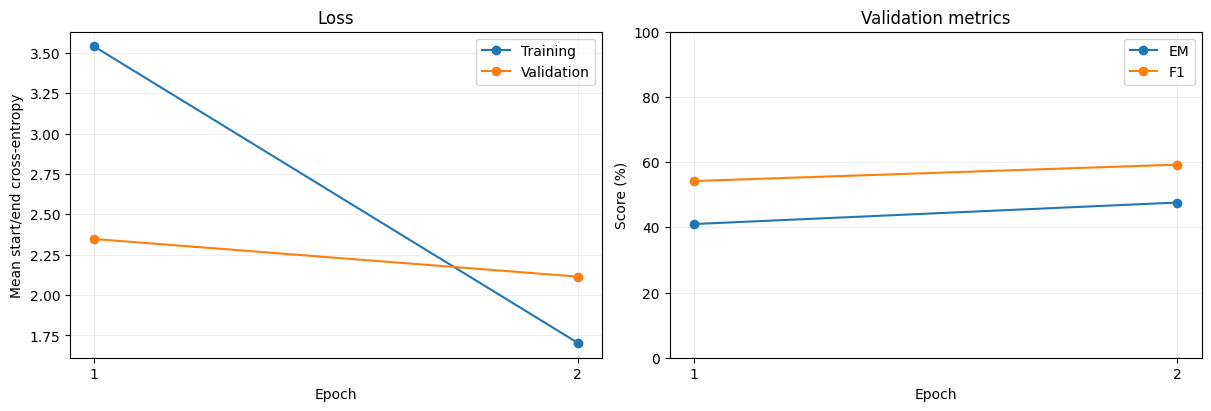

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(
    history["epoch"], history["training_loss"], marker="o", label="Training"
)
axes[0].plot(
    history["epoch"],
    history["validation_loss"],
    marker="o",
    label="Validation",
)
axes[0].set(
    xlabel="Epoch", ylabel="Mean start/end cross-entropy", title="Loss"
)
axes[1].plot(history["epoch"], history["EM"], marker="o", label="EM")
axes[1].plot(history["epoch"], history["F1"], marker="o", label="F1")
axes[1].set(
    xlabel="Epoch",
    ylabel="Score (%)",
    title="Validation metrics",
    ylim=(0, 100),
)
for axis in axes:
    axis.set_xticks(history["epoch"])
    axis.grid(alpha=0.2)
    axis.legend()
fig.savefig(LAB_DIR / "learning_curves.png", dpi=180)
plt.show()
plt.close(fig)

## 7. Experiment 3 - EM vs F1


,Model,n,EM,F1
0,Baseline,1000,0.1,19.260866
1,Fine-tuned Transformer,1000,47.6,59.218091


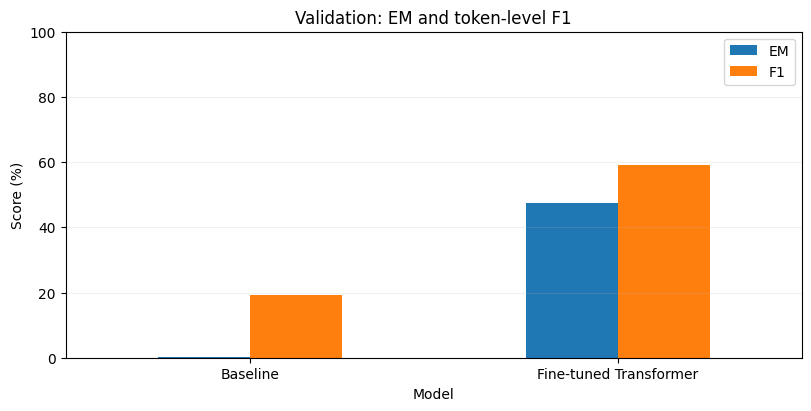

In [7]:
comparison_table = pd.DataFrame(
    [
        {"Model": "Baseline", **baseline_metrics},
        {"Model": "Fine-tuned Transformer", **aggregate_metrics(main_rows)},
    ]
)
display(comparison_table)
fig, axis = plt.subplots(figsize=(8, 4), constrained_layout=True)
comparison_table.set_index("Model")[["EM", "F1"]].plot.bar(ax=axis, rot=0)
axis.set(
    ylabel="Score (%)",
    ylim=(0, 100),
    title="Validation: EM and token-level F1",
)
axis.grid(axis="y", alpha=0.2)
fig.savefig(LAB_DIR / "em_f1_analysis.png", dpi=180)
plt.show()
plt.close(fig)
comparison_table.to_csv(OUTPUT_DIR / "em_f1_comparison.csv", index=False)

## 8. Export genuine examples with EM = 0 and F1 > 0


In [8]:
diagnostic_rows = [{**row, "source": "validation"} for row in main_rows]
diagnostic_cursor = len(val_examples)
diagnostic_model = None


def diagnostic_counts(rows):
    frame = pd.DataFrame(rows)
    return {
        "partial": int(((frame["EM"] == 0) & (frame["F1"] > 0)).sum()),
        **{
            category: int((frame["error_type"] == category).sum())
            for category in ["wrong_start", "wrong_end", "wrong_span"]
        },
    }


def extend_diagnostics():
    global diagnostic_cursor, diagnostic_model
    upper_bound = (
        len(val_pool)
        if DIAGNOSTIC_LIMIT is None
        else min(len(val_pool), DIAGNOSTIC_LIMIT)
    )
    while (
        min(diagnostic_counts(diagnostic_rows).values()) < 5
        and diagnostic_cursor < upper_bound
    ):
        if diagnostic_model is None:
            diagnostic_model, _, _ = ExtractiveQAModel.load_checkpoint(
                CHECKPOINT_DIR, DEVICE
            )
        stop = min(diagnostic_cursor + DIAGNOSTIC_BATCH_SIZE, upper_bound)
        extra_examples = val_pool.select(range(diagnostic_cursor, stop))
        extra_features = make_features(
            extra_examples, tokenizer, MAX_LENGTH, STRIDE
        )
        predictions, _ = predict_features(
            diagnostic_model,
            extra_features,
            extra_examples,
            DEVICE,
            BATCH_SIZE,
            MAX_ANSWER_LENGTH,
        )
        diagnostic_rows.extend(
            {**row, "source": "additional_validation_diagnostics"}
            for row in evaluation_rows(extra_examples, predictions, tokenizer)
        )
        diagnostic_cursor = stop
        print(
            "Diagnostic pool:",
            len(diagnostic_rows),
            diagnostic_counts(diagnostic_rows),
        )
    return pd.DataFrame(diagnostic_rows)


diagnostic_frame = extend_diagnostics()
partial_examples = diagnostic_frame[
    (diagnostic_frame["EM"] == 0) & (diagnostic_frame["F1"] > 0)
]
print_examples(partial_examples, "EM=0 and F1>0")
partial_examples.to_csv(OUTPUT_DIR / "partial_match_examples.csv", index=False)
diagnostic_frame.to_csv(OUTPUT_DIR / "diagnostic_examples.csv", index=False)
if diagnostic_model is not None:
    del diagnostic_model
    diagnostic_model = None
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
print(
    "Additional diagnostic examples are excluded from all experiment "
    "metrics and the test split."
)


EM=0 and F1>0: available=279, displayed=5


,id,source,question,gold,prediction,EM,F1,gold_start,gold_end,pred_start,pred_end,error_type
2,5705f36452bb89140068971b,validation,Which mountain range influenced the split of the regions?,"[""Tehachapis"", ""the Tehachapis"", ""Tehachapis""]",South of the Tehachapis,0.0,50.000000,534,548,525,548,wrong_start
4,56e1c4fce3433e1400423150,validation,BQP and QMA are examples of complexity classes most commonly associated with what type of Turing machine?,"[""quantum"", ""quantum"", ""quantum""]",quantum Turing machines,0.0,50.000000,209,216,209,232,wrong_end
7,56d9a199dc89441400fdb648,validation,How old was Newton in Super Bowl 50?,"[""26"", ""26"", ""26""]","2011. The matchup also pits the top two picks of the 2011 draft against each other: Newton for Carolina and Von Miller for Denver. Manning and Newton also set the record for the largest age difference between opposing Super Bowl quarterbacks at 13 years and 48 days (Manning was 39, Newton was 26",0.0,4.081633,492,494,198,494,wrong_start
9,572a0ce11d046914007796fd,validation,What is the process by which pathogens evade the immune system by hiding inside the host cells called?,"[""intracellular pathogenesis"", ""intracellular pathogenesis"", ""intracellular pathogenesis""]",evasion strategy used by several pathogens to avoid the innate immune system is to hide within the cells of their host (also called intracellular pathogenesis,0.0,16.000000,135,161,3,161,wrong_start
14,56d6f1190d65d21400198274,validation,"Prior to Super Bowl 50, when were the Broncos last there?","[""Super Bowl XLVIII"", ""Super Bowl XLVIII"", ""Super Bowl XLVIII""]",Super Bowl 50,0.0,66.666667,444,461,690,703,wrong_span


Additional diagnostic examples are excluded from all experiment metrics and the test split.


## 9. Experiment 4 - Question/Context Matching


In [9]:
matching_rows = []
for row in main_rows:
    group = (
        "high_overlap"
        if row["lexical_overlap"] >= OVERLAP_THRESHOLD
        else "low_overlap"
    )
    matching_rows.append({**row, "matching_group": group})
matching_table = metric_table(
    matching_rows, "matching_group", ["high_overlap", "low_overlap"]
)
matching_table["threshold"] = OVERLAP_THRESHOLD
display(matching_table)
print(
    "Overlap = fraction of unique question content words "
    "found in the full context."
)
print(
    "low_overlap is an automatic lexical proxy; "
    "paraphrases are not manually annotated."
)
matching_table.to_csv(OUTPUT_DIR / "matching_analysis.csv", index=False)
pd.DataFrame(matching_rows).to_csv(
    OUTPUT_DIR / "matching_examples.csv", index=False
)

,group,n,EM,F1,threshold
0,high_overlap,422,55.687204,66.309454,0.75
1,low_overlap,578,41.695502,54.040659,0.75


Overlap = fraction of unique question content words found in the full context.
low_overlap is an automatic lexical proxy; paraphrases are not manually annotated.


## 10. Experiment 5 - Answer Length


,group,n,EM,F1
0,1,216,50.462963,59.265502
1,2-3,354,55.932203,64.291691
2,4-6,266,50.000000,63.895839
3,7+,164,21.951220,40.617013


Length uses the first reference answer's pretrained-tokenizer subwords without special tokens.


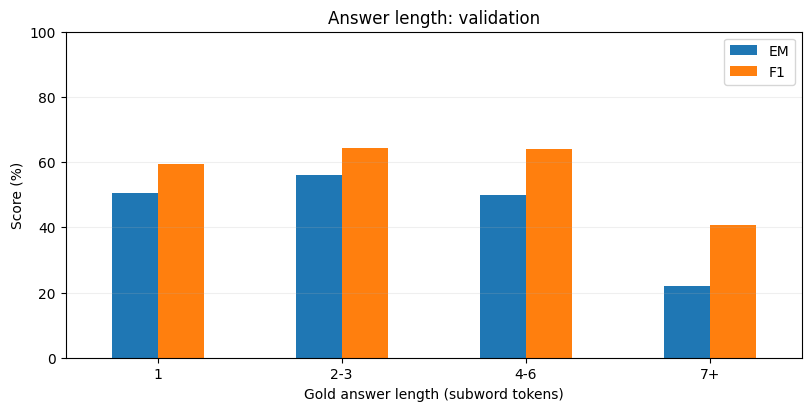

In [10]:
def answer_length_group(length):
    if length == 1:
        return "1"
    if length <= 3:
        return "2-3"
    if length <= 6:
        return "4-6"
    return "7+"


length_rows = [
    {**row, "length_group": answer_length_group(row["answer_tokens"])}
    for row in main_rows
]
length_table = metric_table(
    length_rows, "length_group", ["1", "2-3", "4-6", "7+"]
)
display(length_table)
print(
    "Length uses the first reference answer's pretrained-tokenizer "
    "subwords without special tokens."
)
fig, axis = plt.subplots(figsize=(8, 4), constrained_layout=True)
length_table.set_index("group")[["EM", "F1"]].plot.bar(ax=axis, rot=0)
axis.set(
    xlabel="Gold answer length (subword tokens)",
    ylabel="Score (%)",
    title="Answer length: validation",
    ylim=(0, 100),
)
axis.grid(axis="y", alpha=0.2)
fig.savefig(LAB_DIR / "answer_length_analysis.png", dpi=180)
plt.show()
plt.close(fig)
length_table.to_csv(OUTPUT_DIR / "answer_length_metrics.csv", index=False)

## 11. Error counts and wrong-start/wrong-end/wrong-span examples


In [11]:
error_types = ["wrong_start", "wrong_end", "wrong_span"]
error_counts = pd.DataFrame(
    [
        {
            "error_type": category,
            "count": int((main_frame["error_type"] == category).sum()),
        }
        for category in error_types
    ]
)
display(error_counts)
print(
    "wrong_start: start differs, end matches; "
    "wrong_end: start matches, end differs;"
)
print("wrong_span: both differ. Counts use the original validation split.")
boundary_totals = pd.DataFrame(
    [
        {
            "#wrong_start_including_wrong_span": int(
                main_frame["error_type"]
                .isin(["wrong_start", "wrong_span"])
                .sum()
            ),
            "#wrong_end_including_wrong_span": int(
                main_frame["error_type"]
                .isin(["wrong_end", "wrong_span"])
                .sum()
            ),
            "#wrong_span": int(
                (main_frame["error_type"] == "wrong_span").sum()
            ),
            "#EM_correct_boundary_differs": int(
                (
                    (main_frame["EM"] == 100)
                    & (main_frame["error_type"] != "correct")
                ).sum()
            ),
        }
    ]
)
print("Boundary counts use exact character offsets; EM uses normalization.")
display(boundary_totals)
for category in error_types:
    selected = diagnostic_frame[diagnostic_frame["error_type"] == category]
    print_examples(selected, category)
    selected.to_csv(OUTPUT_DIR / f"{category}_examples.csv", index=False)
error_counts.to_csv(OUTPUT_DIR / "error_counts.csv", index=False)
boundary_totals.to_csv(OUTPUT_DIR / "boundary_totals.csv", index=False)

,error_type,count
0,wrong_start,110
1,wrong_end,89
2,wrong_span,347


wrong_start: start differs, end matches; wrong_end: start matches, end differs;
wrong_span: both differ. Counts use the original validation split.
Boundary counts use exact character offsets; EM uses normalization.


,#wrong_start_including_wrong_span,#wrong_end_including_wrong_span,#wrong_span,#EM_correct_boundary_differs
0,457,436,347,22



wrong_start: available=110, displayed=5


,id,source,question,gold,prediction,EM,F1,gold_start,gold_end,pred_start,pred_end,error_type
2,5705f36452bb89140068971b,validation,Which mountain range influenced the split of the regions?,"[""Tehachapis"", ""the Tehachapis"", ""Tehachapis""]",South of the Tehachapis,0.0,50.000000,534,548,525,548,wrong_start
7,56d9a199dc89441400fdb648,validation,How old was Newton in Super Bowl 50?,"[""26"", ""26"", ""26""]","2011. The matchup also pits the top two picks of the 2011 draft against each other: Newton for Carolina and Von Miller for Denver. Manning and Newton also set the record for the largest age difference between opposing Super Bowl quarterbacks at 13 years and 48 days (Manning was 39, Newton was 26",0.0,4.081633,492,494,198,494,wrong_start
9,572a0ce11d046914007796fd,validation,What is the process by which pathogens evade the immune system by hiding inside the host cells called?,"[""intracellular pathogenesis"", ""intracellular pathogenesis"", ""intracellular pathogenesis""]",evasion strategy used by several pathogens to avoid the innate immune system is to hide within the cells of their host (also called intracellular pathogenesis,0.0,16.000000,135,161,3,161,wrong_start
15,572913626aef051400154a30,validation,What constitutional change was considered?,"[""eliminate the position of Prime Minister and simultaneously reduce the powers of the President"", ""eliminate the position of Prime Minister"", ""eliminate the position of Prime Minister""]",A constitutional change was considered that would eliminate the position of Prime Minister,0.0,62.500000,50,90,0,90,wrong_start
30,56f881e3a6d7ea1400e176f5,validation,What is the earliest that Bach began using Luther hymns?,"[""1707"", ""1707"", ""1707""]","Johann Sebastian Bach included several verses as chorales in his cantatas and based chorale cantatas entirely on them, namely Christ lag in Todes Banden, BWV 4, as early as possibly 1707",0.0,6.250000,232,236,50,236,wrong_start



wrong_end: available=89, displayed=5


,id,source,question,gold,prediction,EM,F1,gold_start,gold_end,pred_start,pred_end,error_type
4,56e1c4fce3433e1400423150,validation,BQP and QMA are examples of complexity classes most commonly associated with what type of Turing machine?,"[""quantum"", ""quantum"", ""quantum""]",quantum Turing machines,0.0,50.000000,209,216,209,232,wrong_end
31,5726e313f1498d1400e8eeb4,validation,What types of pharmacy functions have begun to be outsourced?,"[""high risk preparations and some other compounding functions"", ""high risk preparations and some other compounding functions"", ""high risk preparations and some other compounding functions""]",high risk preparations,0.0,54.545455,663,722,663,685,wrong_end
35,56bebde53aeaaa14008c9339,validation,A replica of what landmark was present at Super Bowl Opening Night?,"[""the Golden Gate Bridge"", ""the Golden Gate Bridge"", ""Golden Gate Bridge.""]",Golden Gate Bridge,100.0,100.000000,366,385,366,384,wrong_end
40,56e1a0dccd28a01900c67a2f,validation,"If two integers are multiplied and output a value, what is this expression set called?","[""set of triples"", ""triple"", ""the set of triples (a, b, c) such that the relation a × b = c holds""]","set of triples (a, b, c) such that the relation a × b = c holds. Deciding whether a given triple is a member of this set corresponds to solving the problem of multiplying two numbers",0.0,58.536585,284,298,284,466,wrong_end
46,571c4132dd7acb1400e4c0b3,validation,Why is Priestley usually given credit for being first to discover oxygen?,"[""published his findings first"", ""he published his findings first"", ""he published his findings first"", ""he published his findings first"", ""Because he published his findings first""]","Because he published his findings first, Priestley is usually given priority in the discovery",0.0,63.157895,768,807,768,861,wrong_end



wrong_span: available=347, displayed=5


,id,source,question,gold,prediction,EM,F1,gold_start,gold_end,pred_start,pred_end,error_type
1,573004bf947a6a140053cf58,validation,The Brotherhood was the only opposition group in Egypt able to do what during elections?,"[""field candidates"", ""field candidates"", ""field candidates""]",semi-legal,0.0,0.000000,247,263,184,194,wrong_span
3,56d99179dc89441400fdb56c,validation,How many games did the Panthers lose in the regular season before Super Bowl 50?,"[""one"", ""1"", ""1""]",one,100.0,100.000000,42,45,193,196,wrong_span
5,56e769dc00c9c71400d770ea,validation,A statement made by Chris Keates caused issues with whom?,"[""child protection and parental rights groups"", ""child protection and parental rights groups"", ""child protection and parental rights groups""]",general secretary,0.0,0.000000,350,393,18,35,wrong_span
13,56f802c6a6d7ea1400e17379,validation,What did giving money to the church absolve the giver from?,"[""punishments"", ""punishments"", ""all punishments""]",indulgences,0.0,0.000000,118,133,85,96,wrong_span
14,56d6f1190d65d21400198274,validation,"Prior to Super Bowl 50, when were the Broncos last there?","[""Super Bowl XLVIII"", ""Super Bowl XLVIII"", ""Super Bowl XLVIII""]",Super Bowl 50,0.0,66.666667,444,461,690,703,wrong_span


## 12. Held-out test evaluation and consolidated results.csv


In [12]:
best_model, _, checkpoint_metadata = ExtractiveQAModel.load_checkpoint(
    CHECKPOINT_DIR, DEVICE
)
test_features = make_features(test_examples, tokenizer, MAX_LENGTH, STRIDE)
test_predictions, test_loss = predict_features(
    best_model,
    test_features,
    test_examples,
    DEVICE,
    BATCH_SIZE,
    MAX_ANSWER_LENGTH,
)
test_rows = evaluation_rows(test_examples, test_predictions, tokenizer)
test_metrics = aggregate_metrics(test_rows)
test_baseline_predictions = {
    str(example["id"]): baseline.predict(
        example["question"], example["context"]
    )
    for example in test_examples
}
test_baseline_rows = evaluation_rows(
    test_examples, test_baseline_predictions, tokenizer, "Baseline"
)
pd.DataFrame(test_rows).to_csv(
    OUTPUT_DIR / "transformer_test.csv", index=False
)
pd.DataFrame(test_baseline_rows).to_csv(
    OUTPUT_DIR / "baseline_test.csv", index=False
)
save_prediction_log(
    OUTPUT_DIR / "test_predictions.jsonl", test_examples, test_predictions
)
del best_model
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

result_rows = []
for row in context_results:
    result_rows.append(
        {
            "experiment": "1_context_length",
            "split": "validation",
            "model": "Transformer",
            "max_length": row["Max length"],
            "stride": row["Stride"],
            "EM": row["EM"],
            "F1": row["F1"],
            "n": row["n"],
            "training_seconds": row["Training time"],
            "wall_seconds": row["Wall time"],
            "best_epoch": row["Best epoch"],
            "train_windows": row["Train windows"],
        }
    )
result_rows.extend(
    {
        "experiment": "2_training_epoch",
        "split": "validation",
        "model": "Transformer",
        "max_length": MAX_LENGTH,
        "stride": STRIDE,
        **row,
    }
    for row in main_run["history"]
)
result_rows.extend(
    {
        "experiment": "3_em_f1",
        "split": "validation",
        "model": row["Model"],
        "EM": row["EM"],
        "F1": row["F1"],
        "n": row["n"],
    }
    for row in comparison_table.to_dict("records")
)
for experiment, table in [
    ("4_matching", matching_table),
    ("5_answer_length", length_table),
]:
    result_rows.extend(
        {
            "experiment": experiment,
            "split": "validation",
            "model": "Transformer",
            **row,
        }
        for row in table.to_dict("records")
    )
result_rows.extend(
    {
        "experiment": "error_counts",
        "split": "validation",
        "model": "Transformer",
        **row,
    }
    for row in error_counts.to_dict("records")
)
result_rows.append(
    {
        "experiment": "boundary_totals",
        "split": "validation",
        "model": "Transformer",
        **boundary_totals.iloc[0].to_dict(),
    }
)
result_rows.extend(
    [
        {
            "experiment": "held_out_test",
            "split": "test",
            "model": "Transformer",
            "test_loss": test_loss,
            **test_metrics,
        },
        {
            "experiment": "held_out_test",
            "split": "test",
            "model": "Baseline",
            **aggregate_metrics(test_baseline_rows),
        },
    ]
)
results = pd.DataFrame(result_rows)
results["seed"] = SEED
results.to_csv(LAB_DIR / "results.csv", index=False)
display(results)
print("Exported:", LAB_DIR / "results.csv")
print(
    "Generated figures:",
    [
        str(LAB_DIR / name)
        for name in [
            "learning_curves.png",
            "em_f1_analysis.png",
            "answer_length_analysis.png",
        ]
    ],
)

QA windows: max_length=384, stride=128:   0%|          | 0/500 [00:00<?, ? examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 500/500 [00:00<00:00, 553.25 examples/s]

QA windows: max_length=384, stride=128: 100%|██████████| 500/500 [00:00<00:00, 517.90 examples/s]

,experiment,split,model,max_length,stride,EM,F1,n,training_seconds,wall_seconds,...,group,threshold,error_type,count,#wrong_start_including_wrong_span,#wrong_end_including_wrong_span,#wrong_span,#EM_correct_boundary_differs,test_loss,seed
0,1_context_length,validation,Transformer,128.0,32.0,46.700000,57.170037,1000.0,128.875697,153.325858,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
1,1_context_length,validation,Transformer,256.0,32.0,49.200000,60.615925,1000.0,121.227084,143.486060,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
2,1_context_length,validation,Transformer,384.0,32.0,45.500000,58.522611,1000.0,169.697718,201.574812,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
3,2_training_epoch,validation,Transformer,384.0,128.0,41.000000,54.188588,1000.0,87.119273,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
4,2_training_epoch,validation,Transformer,384.0,128.0,47.600000,59.218091,1000.0,173.656780,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
5,3_em_f1,validation,Baseline,NaN,NaN,0.100000,19.260866,1000.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
6,3_em_f1,validation,Fine-tuned Transformer,NaN,NaN,47.600000,59.218091,1000.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
7,4_matching,validation,Transformer,NaN,NaN,55.687204,66.309454,422.0,NaN,NaN,...,high_overlap,0.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
8,4_matching,validation,Transformer,NaN,NaN,41.695502,54.040659,578.0,NaN,NaN,...,low_overlap,0.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42
9,5_answer_length,validation,Transformer,NaN,NaN,50.462963,59.265502,216.0,NaN,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42


Exported: C:\Users\Acer\Documents\NLP\lab10\results.csv
Generated figures: ['C:\\Users\\Acer\\Documents\\NLP\\lab10\\learning_curves.png', 'C:\\Users\\Acer\\Documents\\NLP\\lab10\\em_f1_analysis.png', 'C:\\Users\\Acer\\Documents\\NLP\\lab10\\answer_length_analysis.png']
